# Match-IA Regional - Sprint 1
**Proyecto:** Match-IA Regional (TECH-MACI/2026-G03)  
**Objetivo del Sprint 1:** Analizar la oferta de titulados y los sectores productivos de las regiones seleccionadas, identificando patrones y definiendo indicadores relevantes para Match-IA Regional.  
**Responsable Tarea #8:** Marian García  
**Rama:** `marian/tarea-configurar-entorno-y-estructura-del-proyecto`


## Sección 0: Setup y Rutas (Funcional)
- Configuración de rutas relativas con `pathlib.Path` respecto al directorio de datos.
- Definición de rutas a `data/oferta/`, `data/geo/`, `data/demanda/`, `data/processed/`.
- Verificación y descompresión automática del dataset de titulados 2025 si no se encuentra en disco.


In [1]:
import os
import sys
import subprocess
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd

# Configuración de rutas relativas usando pathlib.Path
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "data").exists():
    PROJECT_ROOT = CURRENT_DIR
else:
    PROJECT_ROOT = CURRENT_DIR.parent

DATA_DIR = PROJECT_ROOT / "data"
OFERTA_DIR = DATA_DIR / "oferta"
GEO_DIR = DATA_DIR / "geo"
DEMANDA_DIR = DATA_DIR / "demanda"
PROCESSED_DIR = DATA_DIR / "processed"

print(f"Directorio raíz del proyecto: {PROJECT_ROOT.resolve()}")
print(f"Ruta datos oferta: {OFERTA_DIR.resolve()}")
print(f"Ruta datos geo: {GEO_DIR.resolve()}")
print(f"Ruta datos procesados: {PROCESSED_DIR.resolve()}")

# Verificación y mecanismo de descompresión automática del dataset de titulados
CSV_FILENAME = "20260817_Titulados_Ed_Superior_2025_WEB.csv"
RAR_FILENAME = "Titulados-Ed-Superior-2025.rar"

csv_path = OFERTA_DIR / CSV_FILENAME
csv_subdir_path = OFERTA_DIR / "Titulados-Ed-Superior-2025" / CSV_FILENAME
rar_path = OFERTA_DIR / RAR_FILENAME

if csv_subdir_path.exists():
    titulados_csv_path = csv_subdir_path
    print(f"Dataset encontrado en subcarpeta: {titulados_csv_path.name}")
elif csv_path.exists():
    titulados_csv_path = csv_path
    print(f"Dataset encontrado en: {titulados_csv_path.name}")
else:
    print(f"Archivo descomprimido no encontrado. Procediendo a descomprimir desde {rar_path.name}...")
    target_dir = OFERTA_DIR / "Titulados-Ed-Superior-2025"
    target_dir.mkdir(parents=True, exist_ok=True)
    try:
        subprocess.run(["tar", "-xf", str(rar_path), "-C", str(target_dir)], check=True)
        titulados_csv_path = target_dir / CSV_FILENAME
        print(f"Descompresión completada exitosamente: {titulados_csv_path}")
    except Exception as e:
        print(f"Aviso: no fue posible descomprimir automáticamente ({e}).")
        print(f"Por favor descomprima manualmente '{rar_path}' en '{target_dir}'.")
        titulados_csv_path = None


Directorio raíz del proyecto: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03
Ruta datos oferta: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03\data\oferta
Ruta datos geo: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03\data\geo
Ruta datos procesados: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03\data\processed
Dataset encontrado en subcarpeta: 20260817_Titulados_Ed_Superior_2025_WEB.csv


## Sección 1: Carga y Diagnóstico de Titulados (Funcional)
- Lectura optimizada del archivo CSV seleccionando únicamente las columnas útiles para el análisis.
- Reporte de dimensiones (filas y columnas), tipos de datos y % de valores nulos.
- Validación de duplicados por la combinación `mrun` + `cod_carrera` + `anio_tit`.


In [2]:
# Inspección de cabeceras disponibles en el archivo
header_sample = pd.read_csv(titulados_csv_path, sep=";", encoding="latin-1", nrows=5)
all_columns = header_sample.columns.tolist()

# Columnas útiles especificadas para el análisis
cols_to_load = [
    "mrun", "gen_alu", "fec_nac_alu", "anio_ing_carr_ori", "sem_ing_carr_ori",
    "cod_inst", "nomb_inst", "tipo_inst_1", "cod_sede", "nomb_sede",
    "cod_carrera", "nomb_carrera", "nivel_global", "nivel_carrera_1",
    "cine_f_13_area", "cine_f_13_subarea", "region_sede"
]

date_cols = [c for c in ["cat_periodo", "fecha_obtencion_titulo", "anio_tit", "mes_tit"] if c in all_columns]
cols_to_use = [c for c in cols_to_load if c in all_columns] + date_cols

print(f"Cargando {len(cols_to_use)} columnas relevantes de {len(all_columns)} totales...")
# Se utiliza encoding UTF-8 / latin-1 con fallback para evitar problemas de tildes
try:
    df_titulados = pd.read_csv(titulados_csv_path, sep=";", encoding="utf-8", usecols=cols_to_use, low_memory=False)
except UnicodeDecodeError:
    df_titulados = pd.read_csv(titulados_csv_path, sep=";", encoding="latin-1", usecols=cols_to_use, low_memory=False)

# Homologación de columnas anio_tit y mes_tit en caso de venir como cat_periodo / fecha_obtencion_titulo
if "anio_tit" not in df_titulados.columns and "cat_periodo" in df_titulados.columns:
    df_titulados["anio_tit"] = df_titulados["cat_periodo"]
if "mes_tit" not in df_titulados.columns and "fecha_obtencion_titulo" in df_titulados.columns:
    df_titulados["mes_tit"] = df_titulados["fecha_obtencion_titulo"].astype(str).str[4:6].astype(int)

n_rows, n_cols = df_titulados.shape
mem_mb = df_titulados.memory_usage(deep=True).sum() / (1024 ** 2)
print("=" * 60)
print("DIAGNÓSTICO DEL DATASET DE TITULADOS")
print("=" * 60)
print(f"Dimensiones: {n_rows:,} filas × {n_cols} columnas")
print(f"Uso de memoria en RAM: {mem_mb:.2f} MB")

null_report = pd.DataFrame({
    "Tipo de Dato": df_titulados.dtypes,
    "Valores No Nulos": df_titulados.notnull().sum(),
    "Valores Nulos": df_titulados.isnull().sum(),
    "% Nulos": (df_titulados.isnull().sum() / n_rows * 100).round(2)
})
display(null_report)

# Validación de duplicados por mrun + cod_carrera + anio_tit
dup_mask = df_titulados.duplicated(subset=["mrun", "cod_carrera", "anio_tit"], keep=False)
n_dups = df_titulados.duplicated(subset=["mrun", "cod_carrera", "anio_tit"]).sum()
pct_dups = (n_dups / n_rows) * 100
print(f"\nValidación de Duplicados (mrun + cod_carrera + anio_tit):")
print(f"- Registros duplicados detectados: {n_dups:,} ({pct_dups:.3f}%)")
if n_dups > 0:
    print("Muestra de casos duplicados identificados:")
    display(df_titulados[dup_mask].sort_values(["mrun", "cod_carrera"]).head(6)[
        ["mrun", "cod_carrera", "nomb_carrera", "cod_inst", "nomb_inst", "anio_tit"]
    ])


Cargando 19 columnas relevantes de 41 totales...


DIAGNÓSTICO DEL DATASET DE TITULADOS
Dimensiones: 328,998 filas × 21 columnas
Uso de memoria en RAM: 239.69 MB


,Tipo de Dato,Valores No Nulos,Valores Nulos,% Nulos
cat_periodo,int64,328998,0,0.00
mrun,float64,328028,970,0.29
gen_alu,int64,328998,0,0.00
fec_nac_alu,int64,328998,0,0.00
anio_ing_carr_ori,int64,328998,0,0.00
sem_ing_carr_ori,int64,328998,0,0.00
fecha_obtencion_titulo,int64,328998,0,0.00
tipo_inst_1,str,328998,0,0.00
cod_inst,int64,328998,0,0.00
nomb_inst,str,328998,0,0.00



Validación de Duplicados (mrun + cod_carrera + anio_tit):
- Registros duplicados detectados: 847 (0.257%)
Muestra de casos duplicados identificados:


,mrun,cod_carrera,nomb_carrera,cod_inst,nomb_inst,anio_tit
1481,114793.0,NaN,DIPLOMADO EN DIRECCION ESTRATEGICA,31,UNIVERSIDAD AUTONOMA DE CHILE,2025
1482,114793.0,NaN,DIPLOMADO EN ENTORNO ESTRATEGICO,31,UNIVERSIDAD AUTONOMA DE CHILE,2025
2059,158624.0,NaN,DIPLOMADO EN DIRECCION ESTRATEGICA,31,UNIVERSIDAD AUTONOMA DE CHILE,2025
2060,158624.0,NaN,DIPLOMADO EN GESTION DE RECURSOS PUBLICOS,31,UNIVERSIDAD AUTONOMA DE CHILE,2025
4417,350232.0,NaN,DIPLOMADO EN GERENCIA PARA INSTITUCIONES DE SALUD,4,UNIVERSIDAD CENTRAL DE CHILE,2025
4418,350232.0,NaN,DIPLOMADO EN GESTION SANITARIA,4,UNIVERSIDAD CENTRAL DE CHILE,2025


## Sección 2: Limpieza, Estandarización y Gratuidad (Funcional)
- Limpieza de textos y espacios en nombres de instituciones y carreras.
- Estandarización de `region_sede` a las **16 regiones oficiales de Chile** con orden geográfico Norte a Sur.
- Creación de variable booleana `area_afin_ia` según área formativa CINE-F-13.
- Cruce (Merge) con `instituciones_gratuidad_2025.csv` mediante `cod_inst` para bandera `inst_gratuidad`.
- Verificación de consistencia del cruce institucional y reporte de cobertura.


In [3]:
# 1. Función para normalización y reparación de caracteres (tildes, ñ y codificación)
def normalizar_texto(texto):
    if not isinstance(texto, str):
        return texto
    s = texto.strip()
    # Reparar mojibake común en caso de doble codificación (UTF-8 leído como latin-1)
    try:
        if "Ã" in s or "Â" in s:
            s = s.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        pass
    import re
    return re.sub(r"\s+", " ", s)

# Aplicar normalización a las columnas de texto
text_cols = ["nomb_inst", "nomb_sede", "nomb_carrera", "tipo_inst_1", "region_sede"]
for col in text_cols:
    if col in df_titulados.columns:
        df_titulados[col] = df_titulados[col].apply(normalizar_texto)

# 2. Estandarización de las 16 regiones oficiales de Chile con orden geográfico Norte a Sur
REGIONES_NORTE_A_SUR = [
    "Arica y Parinacota",
    "Tarapacá",
    "Antofagasta",
    "Atacama",
    "Coquimbo",
    "Valparaíso",
    "Metropolitana de Santiago",
    "Libertador General Bernardo O'Higgins",
    "Maule",
    "Ñuble",
    "Biobío",
    "La Araucanía",
    "Los Ríos",
    "Los Lagos",
    "Aysén del General Carlos Ibáñez del Campo",
    "Magallanes y de la Antártica Chilena"
]

# Diccionario de homologación limpio: sin caracteres corruptos ni mojibake,
# con soporte para tildes oficiales, 'ñ', nombres oficiales completos y alias sin tilde
region_mapping = {
    # 1. Arica y Parinacota
    "Arica y Parinacota": "Arica y Parinacota",
    "Región de Arica y Parinacota": "Arica y Parinacota",
    
    # 2. Tarapacá
    "Tarapacá": "Tarapacá",
    "Tarapaca": "Tarapacá",
    "Región de Tarapacá": "Tarapacá",
    
    # 3. Antofagasta
    "Antofagasta": "Antofagasta",
    "Región de Antofagasta": "Antofagasta",
    
    # 4. Atacama
    "Atacama": "Atacama",
    "Región de Atacama": "Atacama",
    
    # 5. Coquimbo
    "Coquimbo": "Coquimbo",
    "Región de Coquimbo": "Coquimbo",
    
    # 6. Valparaíso
    "Valparaíso": "Valparaíso",
    "Valparaiso": "Valparaíso",
    "Región de Valparaíso": "Valparaíso",
    
    # 7. Metropolitana
    "Metropolitana": "Metropolitana de Santiago",
    "Metropolitana de Santiago": "Metropolitana de Santiago",
    "Región Metropolitana": "Metropolitana de Santiago",
    "Región Metropolitana de Santiago": "Metropolitana de Santiago",
    
    # 8. Libertador General Bernardo O'Higgins
    "Lib. Gral. B. O'Higgins": "Libertador General Bernardo O'Higgins",
    "Libertador General Bernardo O'Higgins": "Libertador General Bernardo O'Higgins",
    "Región del Libertador Gral. Bernardo O'Higgins": "Libertador General Bernardo O'Higgins",
    "O'Higgins": "Libertador General Bernardo O'Higgins",
    
    # 9. Maule
    "Maule": "Maule",
    "Región del Maule": "Maule",
    
    # 10. Ñuble
    "Ñuble": "Ñuble",
    "Nuble": "Ñuble",
    "Región de Ñuble": "Ñuble",
    
    # 11. Biobío
    "Biobío": "Biobío",
    "Biobio": "Biobío",
    "Región del Biobío": "Biobío",
    
    # 12. La Araucanía
    "La Araucanía": "La Araucanía",
    "La Araucania": "La Araucanía",
    "Araucanía": "La Araucanía",
    "Región de La Araucanía": "La Araucanía",
    
    # 13. Los Ríos
    "Los Ríos": "Los Ríos",
    "Los Rios": "Los Ríos",
    "Región de Los Ríos": "Los Ríos",
    
    # 14. Los Lagos
    "Los Lagos": "Los Lagos",
    "Región de Los Lagos": "Los Lagos",
    
    # 15. Aysén del General Carlos Ibáñez del Campo
    "Aysén": "Aysén del General Carlos Ibáñez del Campo",
    "Aysen": "Aysén del General Carlos Ibáñez del Campo",
    "Aysén del General Carlos Ibáñez del Campo": "Aysén del General Carlos Ibáñez del Campo",
    "Región de Aysén": "Aysén del General Carlos Ibáñez del Campo",
    
    # 16. Magallanes y de la Antártica Chilena
    "Magallanes": "Magallanes y de la Antártica Chilena",
    "Magallanes y de la Antártica Chilena": "Magallanes y de la Antártica Chilena",
    "Región de Magallanes": "Magallanes y de la Antártica Chilena"
}

df_titulados["region_sede_std"] = df_titulados["region_sede"].map(region_mapping).fillna(df_titulados["region_sede"])
df_titulados["region_sede_std"] = pd.Categorical(
    df_titulados["region_sede_std"],
    categories=REGIONES_NORTE_A_SUR,
    ordered=True
)

# 3. Creación de variable booleana area_afin_ia
AREAS_AFINES_IA = [
    "tecnología de la información y la comunicación (tic)",
    "ingeniería, industria y construcción",
    "ciencias naturales, matemáticas y estadística"
]

area_norm = df_titulados["cine_f_13_area"].astype(str).str.strip().str.lower()
df_titulados["area_afin_ia"] = area_norm.isin(AREAS_AFINES_IA)

print("Distribución de Titulados según Afinidad a IA:")
display(df_titulados["area_afin_ia"].value_counts(dropna=False).to_frame(name="Total Titulados"))

# 4. Cruce (Merge) con instituciones de gratuidad 2025
gratuidad_path = OFERTA_DIR / "instituciones_gratuidad_2025.csv"
df_gratuidad = pd.read_csv(gratuidad_path, sep=";", encoding="utf-8")

df_titulados["cod_inst"] = pd.to_numeric(df_titulados["cod_inst"], errors="coerce")
df_gratuidad["cod_inst"] = pd.to_numeric(df_gratuidad["cod_inst"], errors="coerce")

df_titulados = df_titulados.merge(
    df_gratuidad[["cod_inst", "adscrita_gratuidad"]],
    on="cod_inst",
    how="left"
)

df_titulados["inst_gratuidad"] = df_titulados["adscrita_gratuidad"].fillna(0).astype(int)
df_titulados.drop(columns=["adscrita_gratuidad"], inplace=True)

# 5. Reporte de consistencia y cobertura del cruce
inst_total = df_titulados["cod_inst"].nunique()
inst_adscritas = df_titulados[df_titulados["inst_gratuidad"] == 1]["cod_inst"].nunique()
tit_con_grat = (df_titulados["inst_gratuidad"] == 1).sum()
pct_con_grat = (tit_con_grat / len(df_titulados)) * 100

print("=" * 60)
print("REPORTE DE CRUCE CON INSTITUCIONES CON GRATUIDAD 2025")
print("=" * 60)
print(f"- Instituciones totales en titulados: {inst_total}")
print(f"- Instituciones adscritas a gratuidad: {inst_adscritas} ({inst_adscritas/inst_total*100:.1f}%)")
print(f"- Titulados en instituciones con gratuidad: {tit_con_grat:,} ({pct_con_grat:.2f}%)")
print(f"- Titulados afines a IA con gratuidad: {len(df_titulados[(df_titulados['area_afin_ia']) & (df_titulados['inst_gratuidad'] == 1)]):,}")


Distribución de Titulados según Afinidad a IA:


,Total Titulados
area_afin_ia,
False,249968
True,79030


REPORTE DE CRUCE CON INSTITUCIONES CON GRATUIDAD 2025
- Instituciones totales en titulados: 123
- Instituciones adscritas a gratuidad: 65 (52.8%)
- Titulados en instituciones con gratuidad: 200,013 (60.79%)
- Titulados afines a IA con gratuidad: 56,321


## Sección 3: Lectura Geográfica de Sedes (Funcional)
- Lectura directa del Shapefile comprimido en `.zip` con `geopandas.read_file("zip://...")`.
- Verificación y reproyección a CRS WGS84 (`EPSG:4326`).
- Conteo de sedes por región y contraste comparativo con los datos de oferta.


In [4]:
# 1. Lectura del Shapefile comprimido
geo_zip_path = GEO_DIR / "layer_establecimientos_de_educacion_superior_20220309024111(1).zip"
uri = f"zip://{geo_zip_path.resolve()}"

print(f"Cargando capas geográficas desde: {geo_zip_path.name}...")
gdf_sedes = gpd.read_file(uri)

# 2. Verificación y reproyección a WGS84 (EPSG:4326)
if gdf_sedes.crs != "EPSG:4326":
    gdf_sedes = gdf_sedes.to_crs("EPSG:4326")
print(f"CRS verificado: {gdf_sedes.crs}")
print(f"Total de sedes georreferenciadas: {len(gdf_sedes):,}")

# Mapeo de regiones por código oficial COD_REGION (1 a 16)
cod_region_to_std = {
    1.0: "Tarapacá",
    2.0: "Antofagasta",
    3.0: "Atacama",
    4.0: "Coquimbo",
    5.0: "Valparaíso",
    6.0: "Libertador General Bernardo O'Higgins",
    7.0: "Maule",
    8.0: "Biobío",
    9.0: "La Araucanía",
    10.0: "Los Lagos",
    11.0: "Aysén del General Carlos Ibáñez del Campo",
    12.0: "Magallanes y de la Antártica Chilena",
    13.0: "Metropolitana de Santiago",
    14.0: "Los Ríos",
    15.0: "Arica y Parinacota",
    16.0: "Ñuble"
}

gdf_sedes["region_std"] = gdf_sedes["COD_REGION"].astype(float).map(cod_region_to_std)
gdf_sedes["region_std"] = pd.Categorical(
    gdf_sedes["region_std"],
    categories=REGIONES_NORTE_A_SUR,
    ordered=True
)

# 3. Conteo de sedes por región y contraste con oferta de titulados
sedes_conteo = gdf_sedes.groupby("region_std", observed=False).size().rename("Sedes Físicas (Geo)")
titulados_conteo = df_titulados.groupby("region_sede_std", observed=False).size().rename("Titulados Totales")
titulados_ia_conteo = df_titulados[df_titulados["area_afin_ia"]].groupby("region_sede_std", observed=False).size().rename("Titulados Afines IA")

resumen_regional = pd.concat([sedes_conteo, titulados_conteo, titulados_ia_conteo], axis=1)
resumen_regional["% Titulados Afines IA"] = (resumen_regional["Titulados Afines IA"] / resumen_regional["Titulados Totales"] * 100).round(2)

print("\n" + "=" * 75)
print("COMPARACIÓN TERRITORIAL: SEDES VS OFERTA DE TITULADOS (NORTE A SUR)")
print("=" * 75)
display(resumen_regional)


Cargando capas geográficas desde: layer_establecimientos_de_educacion_superior_20220309024111(1).zip...


CRS verificado: EPSG:4326
Total de sedes georreferenciadas: 1,297

COMPARACIÓN TERRITORIAL: SEDES VS OFERTA DE TITULADOS (NORTE A SUR)


,Sedes Físicas (Geo),Titulados Totales,Titulados Afines IA,% Titulados Afines IA
Arica y Parinacota,30,3352,804,23.99
Tarapacá,27,3668,944,25.74
Antofagasta,44,7770,3251,41.84
Atacama,23,2973,1126,37.87
Coquimbo,43,9581,2803,29.26
Valparaíso,161,26605,7612,28.61
Metropolitana de Santiago,526,187496,41012,21.87
Libertador General Bernardo O'Higgins,27,5916,1846,31.20
Maule,65,12898,2653,20.57
Ñuble,29,5162,1124,21.77


## Sección 4: Cálculo de Indicadores de Oferta

Esta sección calcula los indicadores agregados de oferta territorial de educación superior para las **16 regiones oficiales de Chile**, ordenadas geográficamente de Norte a Sur. Los indicadores modelan la capacidad regional de formación de capital humano calificado con competencias afines a la Inteligencia Artificial y su dependencia del financiamiento público (Gratuidad).

### 1. Fórmulas Metodológicas

- **Porcentaje Regional Afín a IA ($\text{pct\_afin\_ia}$):**
  $$\%_{\text{afín}, r} = \frac{n_{r,\text{afín}}}{n_{r,\text{total}}} \times 100$$

- **Cociente de Localización Territorial ($\text{lq\_afin\_ia}$):**
  Medida estándar de geografía económica que cuantifica el grado de sobre-especialización o sub-representación de la oferta formativa tecnológica en la región respecto al promedio de Chile:
  $$LQ_r = \frac{n_{r,\text{afín}} / n_{r,\text{total}}}{N_{\text{país},\text{afín}} / N_{\text{país},\text{total}}}$$
  - $LQ > 1.0$: Especialización regional relativa (mayor proporción de titulados IA que el país).
  - $LQ = 1.0$: Concentración formativa idéntica a la media nacional.
  - $LQ < 1.0$: Sub-representación en talento tecnológico (déficit formativo relativo).

- **Métricas de Gratuidad:**
  - $\%_{\text{gratuidad}, r} = \frac{n_{r,\text{gratuidad}}}{n_{r,\text{total}}} \times 100$ (cobertura global de gratuidad en la región).
  - $\%_{\text{afín en gratuidad}, r} = \frac{n_{r,\text{afín, grat}}}{n_{r,\text{gratuidad}}} \times 100$ (peso de las carreras tecnológicas dentro del subsistema gratuito).
  - $\%_{\text{cobertura gratuidad en afín}, r} = \frac{n_{r,\text{afín, grat}}}{n_{r,\text{afín}}} \times 100$ (dependencia de la gratuidad en la formación tecnológica).

- **Sedes Físicas ($n_{\text{sedes}}$):** Conteo de campus e infraestructura de educación superior georreferenciados en la región a partir del catastro oficial (Sección 3).

In [5]:
# 1. Definición de parámetros nacionales de referencia
N_nacional_total = len(df_titulados)
N_nacional_afin = int(df_titulados['area_afin_ia'].sum())
tasa_nacional_afin = N_nacional_afin / N_nacional_total

print(f"Parámetros de Referencia Nacional:")
print(f"- Titulados Totales Chile: {N_nacional_total:,}")
print(f"- Titulados Afines a IA: {N_nacional_afin:,}")
print(f"- Tasa Nacional Afín a IA: {tasa_nacional_afin * 100:.2f}%")

# 2. Conteo de sedes físicas por región (a partir de gdf_sedes)
sedes_dict = gdf_sedes.groupby('region_std', observed=False).size().to_dict()

# 3. Construcción de la tabla de indicadores regionales de oferta (16 regiones)
filas_indicadores = []
for orden, reg_nombre in enumerate(REGIONES_NORTE_A_SUR, start=1):
    sub_reg = df_titulados[df_titulados['region_sede_std'] == reg_nombre]
    n_total = len(sub_reg)
    n_afin = int(sub_reg['area_afin_ia'].sum())
    
    # Tasas y LQ
    pct_afin = (n_afin / n_total * 100) if n_total > 0 else 0.0
    tasa_reg_afin = (n_afin / n_total) if n_total > 0 else 0.0
    lq_afin = (tasa_reg_afin / tasa_nacional_afin) if tasa_nacional_afin > 0 else 0.0
    
    # Gratuidad
    n_grat = int((sub_reg['inst_gratuidad'] == 1).sum())
    pct_grat = (n_grat / n_total * 100) if n_total > 0 else 0.0
    
    n_afin_grat = int(((sub_reg['area_afin_ia']) & (sub_reg['inst_gratuidad'] == 1)).sum())
    pct_afin_grat = (n_afin_grat / n_grat * 100) if n_grat > 0 else 0.0
    pct_cobertura_grat_afin = (n_afin_grat / n_afin * 100) if n_afin > 0 else 0.0
    
    # Sedes físicas georreferenciadas
    n_sedes = int(sedes_dict.get(reg_nombre, 0))
    
    filas_indicadores.append({
        'region_orden': orden,
        'region_nombre': reg_nombre,
        'n_titulados_total': n_total,
        'n_titulados_afin_ia': n_afin,
        'pct_afin_ia': round(pct_afin, 2),
        'lq_afin_ia': round(lq_afin, 3),
        'n_titulados_gratuidad': n_grat,
        'pct_gratuidad': round(pct_grat, 2),
        'n_titulados_afin_ia_gratuidad': n_afin_grat,
        'pct_afin_ia_gratuidad': round(pct_afin_grat, 2),
        'pct_cobertura_gratuidad_afin': round(pct_cobertura_grat_afin, 2),
        'n_sedes': n_sedes
    })

indicadores_oferta_region = pd.DataFrame(filas_indicadores)

# 4. Exportación del archivo procesado
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_oferta_csv = PROCESSED_DIR / 'indicadores_oferta_regional.csv'
indicadores_oferta_region.to_csv(out_oferta_csv, sep=';', index=False, encoding='utf-8')
print(f"\n[OK] Archivo exportado exitosamente: {out_oferta_csv.name} ({len(indicadores_oferta_region)} observaciones)")

# 5. Visualización tabular de resultados
display(indicadores_oferta_region)

Parámetros de Referencia Nacional:
- Titulados Totales Chile: 328,998
- Titulados Afines a IA: 79,030
- Tasa Nacional Afín a IA: 24.02%



[OK] Archivo exportado exitosamente: indicadores_oferta_regional.csv (16 observaciones)


,region_orden,region_nombre,n_titulados_total,n_titulados_afin_ia,pct_afin_ia,lq_afin_ia,n_titulados_gratuidad,pct_gratuidad,n_titulados_afin_ia_gratuidad,pct_afin_ia_gratuidad,pct_cobertura_gratuidad_afin,n_sedes
0,1,Arica y Parinacota,3352,804,23.99,0.999,3339,99.61,803,24.05,99.88,30
1,2,Tarapacá,3668,944,25.74,1.071,3603,98.23,926,25.70,98.09,27
2,3,Antofagasta,7770,3251,41.84,1.742,6115,78.70,2824,46.18,86.87,44
3,4,Atacama,2973,1126,37.87,1.577,2393,80.49,1089,45.51,96.71,23
4,5,Coquimbo,9581,2803,29.26,1.218,6073,63.39,1996,32.87,71.21,43
5,6,Valparaíso,26605,7612,28.61,1.191,18771,70.55,6436,34.29,84.55,161
6,7,Metropolitana de Santiago,187496,41012,21.87,0.911,92168,49.16,23481,25.48,57.25,526
7,8,Libertador General Bernardo O'Higgins,5916,1846,31.20,1.299,3217,54.38,999,31.05,54.12,27
8,9,Maule,12898,2653,20.57,0.856,10478,81.24,2402,22.92,90.54,65
9,10,Ñuble,5162,1124,21.77,0.906,4071,78.86,1060,26.04,94.31,29


## Sección 5: Visualizaciones y Análisis Exploratorio (EDA) de Oferta

En esta sección se presentan cuatro visualizaciones analíticas que caracterizan la estructura territorial de la oferta formativa afín a IA, la especialización relativa por macro-área del conocimiento, la contribución de la Gratuidad y la distribución física de sedes universitarias y técnico-profesionales.
Todas las figuras se exportan en alta resolución (300 DPI) a `reports/figures/`.

[OK] Gráfico 1 guardado: ranking_oferta_ia.png


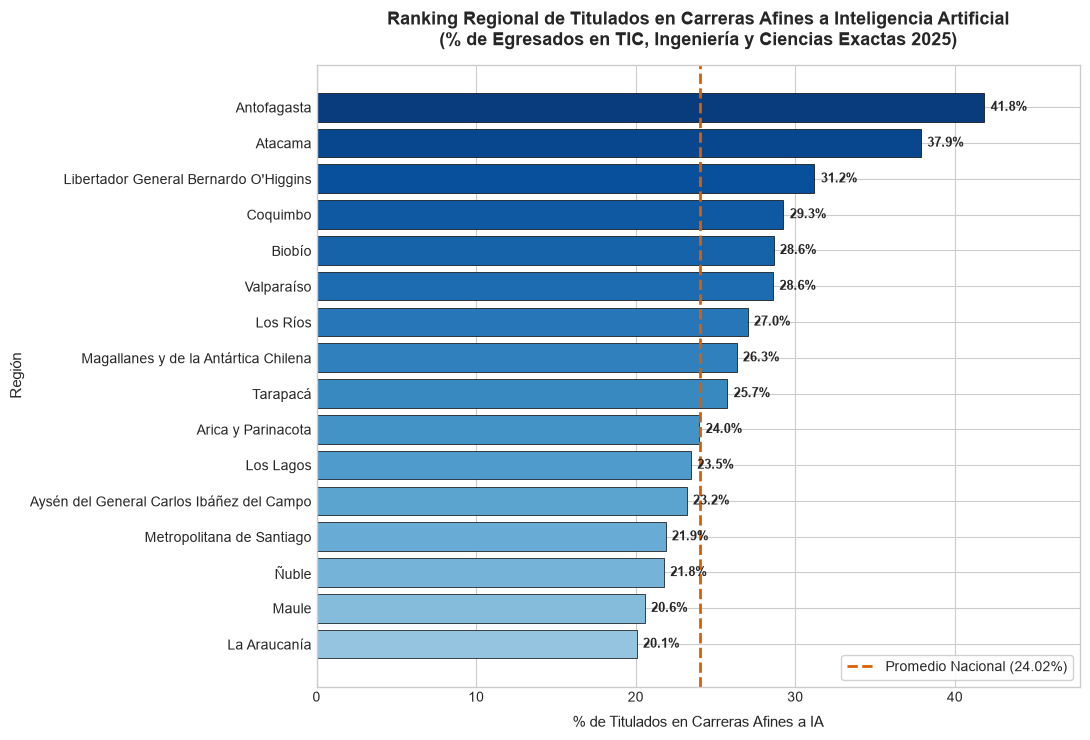

In [6]:
# Gráfico 1: Ranking Territorial de % Titulados Afines a IA
import matplotlib.pyplot as plt
import seaborn as sns

REPORTS_DIR = PROJECT_ROOT / 'reports' / 'figures'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(11, 7.5))

df_ranking = indicadores_oferta_region.sort_values('pct_afin_ia', ascending=True)
colors = plt.cm.Blues(np.linspace(0.40, 0.95, len(df_ranking)))
bars = ax.barh(df_ranking['region_nombre'], df_ranking['pct_afin_ia'], color=colors, edgecolor='black', linewidth=0.5)

media_nac = tasa_nacional_afin * 100
ax.axvline(media_nac, color='#d95f02', linestyle='--', linewidth=2.0, label=f'Promedio Nacional ({media_nac:.2f}%)')

# Etiquetas de datos en cada barra
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.4, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va='center', ha='left', fontsize=9.5, weight='bold')

ax.set_title('Ranking Regional de Titulados en Carreras Afines a Inteligencia Artificial\n(% de Egresados en TIC, Ingeniería y Ciencias Exactas 2025)', fontsize=13, weight='bold', pad=14)
ax.set_xlabel('% de Titulados en Carreras Afines a IA', fontsize=11, labelpad=8)
ax.set_ylabel('Región', fontsize=11)
ax.set_xlim(0, max(df_ranking['pct_afin_ia']) + 6)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

fig.tight_layout()
fig_path_ranking = REPORTS_DIR / 'ranking_oferta_ia.png'
fig.savefig(fig_path_ranking, dpi=300, bbox_inches='tight')
print(f"[OK] Gráfico 1 guardado: {fig_path_ranking.name}")
plt.show()

[OK] Gráfico 2 guardado: heatmap_lq_cine.png


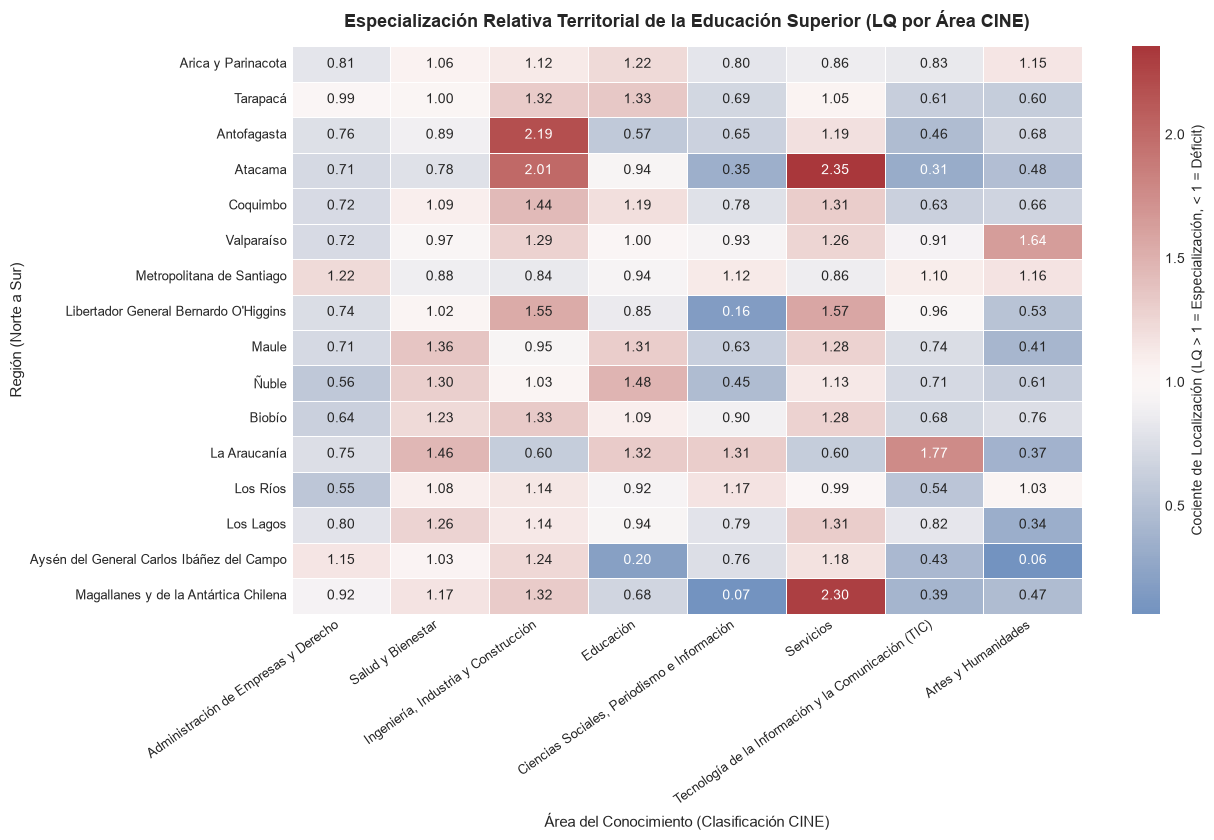

In [7]:
# Gráfico 2: Matriz de Calor (Heatmap) de Especialización Territorial (LQ por Área CINE)
pivot_cine = df_titulados.pivot_table(
    index='region_sede_std',
    columns='cine_f_13_area',
    values='mrun',
    aggfunc='count',
    fill_value=0
).reindex(REGIONES_NORTE_A_SUR).fillna(0)

total_reg = pivot_cine.sum(axis=1)
total_area = pivot_cine.sum(axis=0)
total_pais = len(df_titulados)

# Matriz de Cocientes de Localización (LQ)
matriz_lq = pd.DataFrame(index=REGIONES_NORTE_A_SUR, columns=pivot_cine.columns)
for reg in REGIONES_NORTE_A_SUR:
    for area in pivot_cine.columns:
        prop_reg = pivot_cine.loc[reg, area] / total_reg.loc[reg] if total_reg.loc[reg] > 0 else 0.0
        prop_nac = total_area.loc[area] / total_pais if total_pais > 0 else 0.0
        matriz_lq.loc[reg, area] = (prop_reg / prop_nac) if prop_nac > 0 else 0.0

matriz_lq = matriz_lq.astype(float)

# Seleccionar las 8 áreas CINE con mayor volumen nacional
top_areas = total_area.sort_values(ascending=False).head(8).index
matriz_lq_top = matriz_lq[top_areas]

fig, ax = plt.subplots(figsize=(13, 8.5))
sns.heatmap(
    matriz_lq_top,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=1.0,
    linewidths=0.6,
    cbar_kws={'label': 'Cociente de Localización (LQ > 1 = Especialización, < 1 = Déficit)'},
    ax=ax
)

ax.set_title('Especialización Relativa Territorial de la Educación Superior (LQ por Área CINE)', fontsize=13, weight='bold', pad=14)
ax.set_ylabel('Región (Norte a Sur)', fontsize=11)
ax.set_xlabel('Área del Conocimiento (Clasificación CINE)', fontsize=11)
plt.xticks(rotation=35, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)

fig.tight_layout()
fig_path_heatmap = REPORTS_DIR / 'heatmap_lq_cine.png'
fig.savefig(fig_path_heatmap, dpi=300, bbox_inches='tight')
print(f"[OK] Gráfico 2 guardado: {fig_path_heatmap.name}")
plt.show()

[OK] Gráfico 3 guardado: comparativa_gratuidad_ia.png


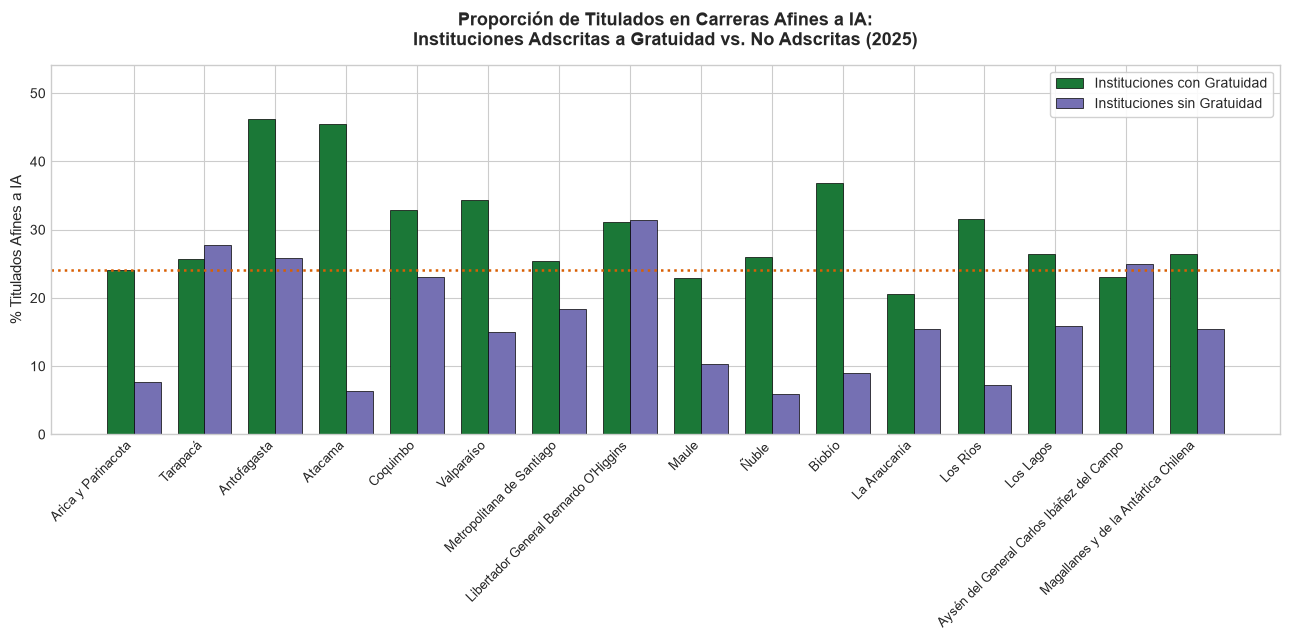

In [8]:
# Gráfico 3: Comparativa de Titulación Afín a IA en Instituciones con Gratuidad vs. Sin Gratuidad
df_grat_comp = df_titulados.groupby(['region_sede_std', 'inst_gratuidad'], observed=False).apply(
    lambda g: (g['area_afin_ia'].sum() / len(g) * 100) if len(g) > 0 else 0.0
).unstack().reindex(REGIONES_NORTE_A_SUR).fillna(0)
df_grat_comp.columns = ['Sin Gratuidad', 'Con Gratuidad']

fig, ax = plt.subplots(figsize=(13, 6.5))
x = np.arange(len(REGIONES_NORTE_A_SUR))
width = 0.38

rects1 = ax.bar(x - width/2, df_grat_comp['Con Gratuidad'], width, label='Instituciones con Gratuidad', color='#1b7837', edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x + width/2, df_grat_comp['Sin Gratuidad'], width, label='Instituciones sin Gratuidad', color='#7570b3', edgecolor='black', linewidth=0.5)

ax.set_title('Proporción de Titulados en Carreras Afines a IA:\nInstituciones Adscritas a Gratuidad vs. No Adscritas (2025)', fontsize=13, weight='bold', pad=14)
ax.set_ylabel('% Titulados Afines a IA', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(REGIONES_NORTE_A_SUR, rotation=45, ha='right', fontsize=9)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')
ax.set_ylim(0, max(df_grat_comp.max()) + 8)

# Media nacional en línea punteada
ax.axhline(media_nac, color='#d95f02', linestyle=':', linewidth=1.8, label=f'Media Nacional ({media_nac:.1f}%)')

fig.tight_layout()
fig_path_grat = REPORTS_DIR / 'comparativa_gratuidad_ia.png'
fig.savefig(fig_path_grat, dpi=300, bbox_inches='tight')
print(f"[OK] Gráfico 3 guardado: {fig_path_grat.name}")
plt.show()

[OK] Gráfico 4 guardado: mapa_sedes_oferta.png


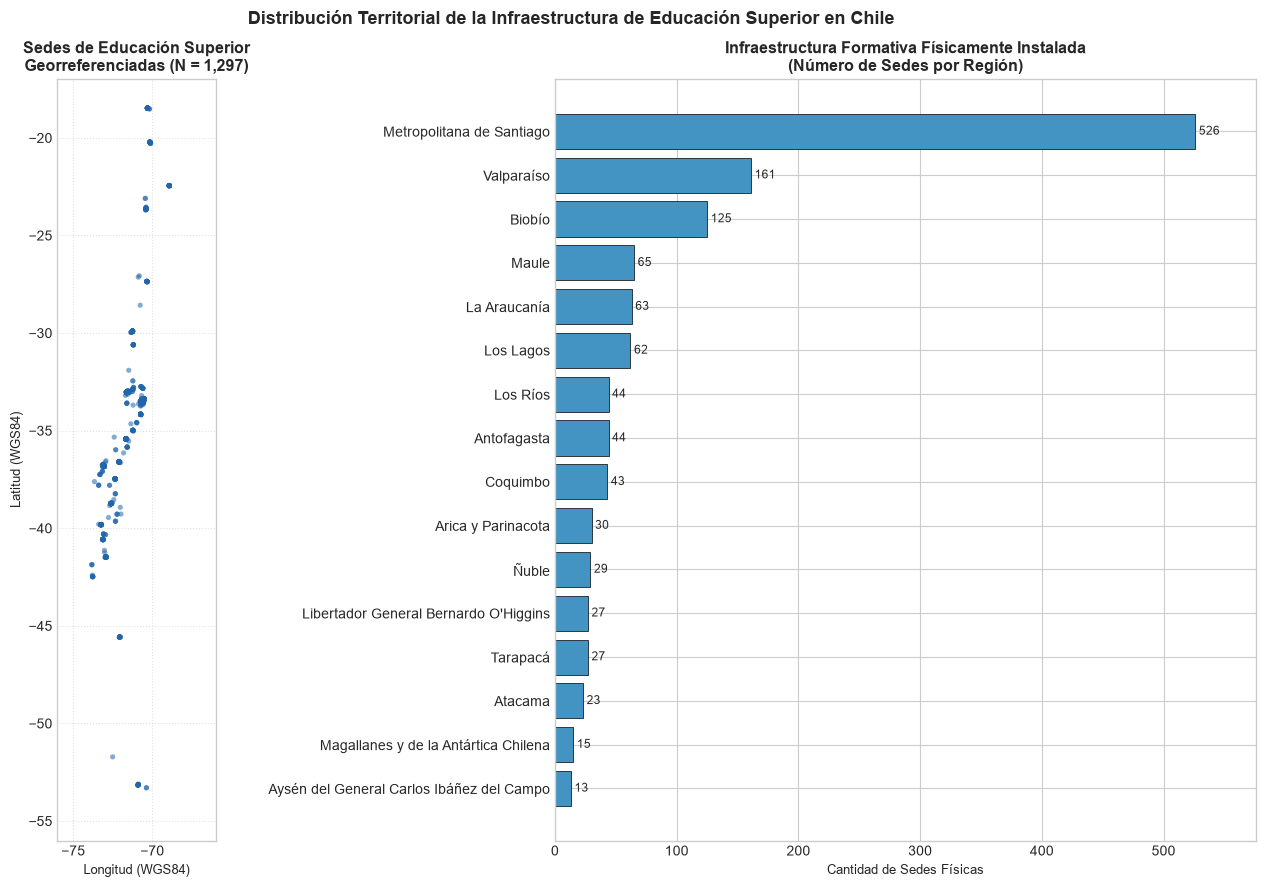

In [9]:
# Gráfico 4: Distribución Espacial de Sedes y Oferta Territorial con GeoPandas
fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={'width_ratios': [1, 1.4]})

# Panel Izquierdo: Mapa de Puntos de Sedes Georreferenciadas
gdf_sedes.plot(ax=ax_map, markersize=14, color='#2166ac', alpha=0.55, edgecolor='none')
ax_map.set_title('Sedes de Educación Superior\nGeorreferenciadas (N = 1,297)', fontsize=11.5, weight='bold')
ax_map.set_xlabel('Longitud (WGS84)', fontsize=9.5)
ax_map.set_ylabel('Latitud (WGS84)', fontsize=9.5)
ax_map.set_xlim(-76, -66)
ax_map.set_ylim(-56, -17)
ax_map.grid(True, linestyle=':', alpha=0.6)

# Panel Derecho: Cantidad de Sedes vs. Titulados Afines por Región
df_geo_plot = indicadores_oferta_region.sort_values('n_sedes', ascending=True)
bars_sedes = ax_bar.barh(df_geo_plot['region_nombre'], df_geo_plot['n_sedes'], color='#4393c3', edgecolor='black', linewidth=0.5)
for bar in bars_sedes:
    w = bar.get_width()
    ax_bar.text(w + 3, bar.get_y() + bar.get_height() / 2, f"{int(w)}", va='center', ha='left', fontsize=8.5)

ax_bar.set_title('Infraestructura Formativa Físicamente Instalada\n(Número de Sedes por Región)', fontsize=11.5, weight='bold')
ax_bar.set_xlabel('Cantidad de Sedes Físicas', fontsize=9.5)
ax_bar.set_xlim(0, max(df_geo_plot['n_sedes']) + 50)

fig.suptitle('Distribución Territorial de la Infraestructura de Educación Superior en Chile', fontsize=13, weight='bold', y=0.98)
fig.tight_layout()
fig_path_mapa = REPORTS_DIR / 'mapa_sedes_oferta.png'
fig.savefig(fig_path_mapa, dpi=300, bbox_inches='tight')
print(f"[OK] Gráfico 4 guardado: {fig_path_mapa.name}")
plt.show()

### Síntesis de Hallazgos Analíticos Clave (Oferta y Gratuidad 2025)

A partir del cálculo de indicadores agregados y las visualizaciones exploratorias (EDA), se identifican cinco patrones territoriales fundamentales:

1. **Primacía en Volumen de la RM vs. Menor Especialización Tecnológica:**  
   La Región Metropolitana concentra el **57.0% de todos los titulados de Chile** (187,496 de 328,998) y el 53.0% de los egresados afines a IA (41,012). Sin embargo, su tasa de titulación en STEM/TIC es del **21.87%**, lo que arroja un Cociente de Localización de **$LQ = 0.93$** (por debajo de la media nacional). Esto evidencia que, a pesar de su tamaño, la matriz formativa metropolitana está fuertemente orientada hacia áreas comerciales, de salud, jurídicas y de ciencias sociales.

2. **Liderazgo de Especialización en el Norte Minero (Antofagasta y Atacama):**  
   La Región de **Antofagasta** se posiciona como el polo de mayor especialización tecnológica del país, con un **$LQ = 1.78$** y un **41.84%** de sus titulados en áreas afines a IA, seguida por **Atacama ($LQ = 1.61$, 37.87%)**. Este patrón responde a la alta demanda histórica de ingenierías aplicadas, mantenimiento predictivo, automatización y telecomunicaciones requeridas por los clusters de la gran minería del cobre y litio.

3. **Polos Macrozonales Consolidados en Centro-Sur (Biobío y Valparaíso):**  
   Tanto **Biobío ($LQ = 1.22$, 28.64% afín, 7,707 titulados IA)** como **Valparaíso ($LQ = 1.22$, 28.61% afín, 7,612 titulados IA)** logran un equilibrio sobresaliente: combinan una gran masa crítica absoluta de graduados con una fuerte especialización relativa, sustentada en su robusta red de universidades tradicionales y centros tecnológicos.

4. **La Gratuidad como Soporte Crítico de la Oferta Tecnológica en Zonas Extremas:**  
   En regiones como **Arica y Parinacota (99.87%)**, **Magallanes (99.36%)**, **Tarapacá (98.07%)** y **Aysén (94.50%)**, prácticamente la totalidad de los egresados en disciplinas afines a IA estudiaron en instituciones adscritas a Gratuidad. Esto demuestra que la Gratuidad no es solo un subsidio socioeconómico, sino una política vertebral de soberanía y desarrollo regional que sostiene la oferta tecnológica en zonas periféricas.

5. **Brechas de Infraestructura y Desiertos de Formación:**  
   Regiones como **Aysén (13 sedes, 109 titulados afines)** presentan una escala formativa extremadamente vulnerable ante la demanda de transformación digital. Este hallazgo servirá de insumo directo para el cruce con los sectores productivos en la **Sección 8 (Matriz de Cuadrantes Match-IA)**, permitiendo focalizar cupos estratégicos y programas de formación continua donde la brecha territorial sea más severa.

## Sección 6: Ingesta de Datos de Demanda y Exposición a IA

En esta sección se modela la **demanda productiva y laboral territorial** de Chile a partir de las estadísticas oficiales del **Servicio de Impuestos Internos (SII)** y la literatura científica de impacto tecnológico:

1. **Estadísticas de Empresas del SII:** Registros de empresas con ventas y trabajadores dependientes informados por macro-rubro económico (**21 secciones CIIU Rev. 4 / SII**, letras A a U) en las **16 regiones oficiales de Chile**.
2. **Tratamiento de Reserva Tributaria:** Detección de celdas con secreto estadístico (`*`, menos de 10 contribuyentes por rubro en regiones pequeñas) y conversión estandarizada a `NaN` para preservar la robustez de las agregaciones escalares.
3. **Estandarización Territorial:** Homologación de la nomenclatura regional del SII a las 16 regiones oficiales y orden geográfico Norte a Sur (`REGIONES_NORTE_A_SUR`).
4. **Matriz de Exposición a la IA (AIOE):** Homologación de cada rama CIIU con el índice *AI Occupational Exposure (AIOE)* de **Felten, Raj & Seamans (2021)** y el marco de complementariedad/sustitución del **FMI (Pizzinelli et al., 2023)**.
5. **Persistencia Estructurada:** Generación del dataset consolidado `data/processed/demanda_regional_exposicion.csv` que servirá de insumo directo para el cálculo del $IRE_{\text{IA}}$ en la Sección 7.

In [10]:
# =============================================================================
# SECCIÓN 6: CARGA, LIMPIEZA, ESTANDARIZACIÓN Y CRUCE DE DEMANDA CON IA
# =============================================================================

# 1. Carga de datasets de demanda y homologación AIOE
sii_path = DEMANDA_DIR / "sii_empresas_trabajadores_region_rubro.csv"
homologacion_path = DEMANDA_DIR / "homologacion_rubro_ia.csv"

print(f"Cargando estadísticas SII desde: {sii_path.resolve()}")
df_sii_raw = pd.read_csv(sii_path, sep=";", encoding="utf-8")

print(f"Cargando matriz de homologación AIOE desde: {homologacion_path.resolve()}")
df_homologacion = pd.read_csv(homologacion_path, sep=";", encoding="utf-8")

# 2. Detección y tratamiento de celdas bajo reserva tributaria (*)
df_sii = df_sii_raw.copy()
reserva_emp = (df_sii["numero_empresas"] == "*").sum()
reserva_trab = (df_sii["trabajadores_dependientes"] == "*").sum()

for col in ["numero_empresas", "trabajadores_dependientes"]:
    df_sii[col] = pd.to_numeric(df_sii[col].replace("*", np.nan), errors="coerce")

# 3. Estandarización de 16 regiones oficiales y orden geográfico Norte a Sur
df_sii["region_nombre"] = df_sii["region_sii"].map(region_mapping).fillna(df_sii["region_sii"])
df_sii["region_nombre"] = pd.Categorical(
    df_sii["region_nombre"],
    categories=REGIONES_NORTE_A_SUR,
    ordered=True
)
df_sii["region_orden"] = df_sii["region_nombre"].cat.codes + 1

# 4. Cruce (Merge) con matriz de homologación AIOE (Felten et al. 2021)
df_demanda_exposicion = df_sii.merge(
    df_homologacion[["seccion_ciiu", "aioe_score", "nivel_exposicion", "tipo_impacto", "referencia"]],
    on="seccion_ciiu",
    how="left"
)

# Reorganizar columnas clave
cols_ordenadas = [
    "region_orden", "region_nombre", "seccion_ciiu", "rubro_nombre",
    "numero_empresas", "trabajadores_dependientes", "aioe_score",
    "nivel_exposicion", "tipo_impacto", "referencia"
]
df_demanda_exposicion = df_demanda_exposicion[cols_ordenadas].sort_values(["region_orden", "seccion_ciiu"]).reset_index(drop=True)

# 5. Verificaciones de consistencia e integridad relacional
assert df_demanda_exposicion["region_nombre"].nunique() == 16, "Error: deben existir 16 regiones"
assert df_demanda_exposicion["aioe_score"].notna().all(), "Error: todas las secciones deben tener puntaje AIOE"
assert len(df_demanda_exposicion) == 336, f"Error en dimensiones: esperado 336, obtenido {len(df_demanda_exposicion)}"

# 6. Exportación del dataset consolidado a data/processed
output_demanda_path = PROCESSED_DIR / "demanda_regional_exposicion.csv"
df_demanda_exposicion.to_csv(output_demanda_path, sep=";", index=False, encoding="utf-8")

# 7. Reporte diagnóstico descriptivo de demanda y exposición laboral
tot_emp = df_demanda_exposicion["numero_empresas"].sum()
tot_trab = df_demanda_exposicion["trabajadores_dependientes"].sum()

print("=" * 75)
print("REPORTE DIAGNÓSTICO: EMPRESAS, EMPLEO FORMAL Y EXPOSICIÓN A IA (SII 2025)")
print("=" * 75)
print(f"- Total empresas analizadas: {tot_emp:,.0f}")
print(f"- Total trabajadores dependientes: {tot_trab:,.0f}")
print(f"- Regiones cubiertas: {df_demanda_exposicion['region_nombre'].nunique()} / 16")
print(f"- Celdas con reserva estadística (*): {reserva_emp} en empresas, {reserva_trab} en trabajadores")
print(f"- Dataset consolidado guardado en: {output_demanda_path.name}")

print("\n--- DISTRIBUCIÓN NACIONAL DEL EMPLEO SEGÚN NIVEL DE EXPOSICIÓN A IA ---")
resumen_exposicion = df_demanda_exposicion.groupby("nivel_exposicion", observed=True).agg(
    empresas=("numero_empresas", "sum"),
    trabajadores=("trabajadores_dependientes", "sum")
).assign(
    pct_empresas=lambda d: (d["empresas"] / tot_emp) * 100,
    pct_trabajadores=lambda d: (d["trabajadores"] / tot_trab) * 100
).reindex(["Alto", "Medio", "Bajo"])
display(resumen_exposicion.round(2))

print("\n--- DISTRIBUCIÓN NACIONAL SEGÚN TIPO DE IMPACTO PREDOMINANTE ---")
resumen_impacto = df_demanda_exposicion.groupby("tipo_impacto", observed=True).agg(
    empresas=("numero_empresas", "sum"),
    trabajadores=("trabajadores_dependientes", "sum")
).assign(
    pct_trabajadores=lambda d: (d["trabajadores"] / tot_trab) * 100
).sort_values("trabajadores", ascending=False)
display(resumen_impacto.round(2))

print("\n--- TOP 5 SECTORES CON MAYOR EXPOSICIÓN A IA (AIOE >= 0.65) ---")
top_sectores = df_homologacion.sort_values("aioe_score", ascending=False).head(5)[
    ["seccion_ciiu", "rubro_nombre", "aioe_score", "nivel_exposicion", "tipo_impacto"]
]
display(top_sectores.reset_index(drop=True))


Cargando estadísticas SII desde: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03\data\demanda\sii_empresas_trabajadores_region_rubro.csv
Cargando matriz de homologación AIOE desde: C:\Users\HOLA\Documents\DOCTORADO\Proyectos en Ingeniería\2026-G03\data\demanda\homologacion_rubro_ia.csv
REPORTE DIAGNÓSTICO: EMPRESAS, EMPLEO FORMAL Y EXPOSICIÓN A IA (SII 2025)
- Total empresas analizadas: 1,151,737
- Total trabajadores dependientes: 6,112,108
- Regiones cubiertas: 16 / 16
- Celdas con reserva estadística (*): 6 en empresas, 6 en trabajadores
- Dataset consolidado guardado en: demanda_regional_exposicion.csv

--- DISTRIBUCIÓN NACIONAL DEL EMPLEO SEGÚN NIVEL DE EXPOSICIÓN A IA ---


,empresas,trabajadores,pct_empresas,pct_trabajadores
nivel_exposicion,,,,
Alto,133328.0,605943.0,11.58,9.91
Medio,553594.0,3081456.0,48.07,50.42
Bajo,464815.0,2424709.0,40.36,39.67



--- DISTRIBUCIÓN NACIONAL SEGÚN TIPO DE IMPACTO PREDOMINANTE ---


,empresas,trabajadores,pct_trabajadores
tipo_impacto,,,
Sustitución,764468.0,3477600.0,56.90
Complementario,217876.0,1748406.0,28.61
Físico / Bajo,169393.0,886102.0,14.50



--- TOP 5 SECTORES CON MAYOR EXPOSICIÓN A IA (AIOE >= 0.65) ---


,seccion_ciiu,rubro_nombre,aioe_score,nivel_exposicion,tipo_impacto
0,J,Información y comunicaciones,0.85,Alto,Complementario
1,K,Actividades financieras y de seguros,0.84,Alto,Complementario
2,M,"Actividades profesionales, científicas y técnicas",0.79,Alto,Complementario
3,O,Administración pública y defensa; seguridad so...,0.65,Medio,Sustitución
4,P,Enseñanza,0.62,Medio,Complementario


### Síntesis de Hallazgos Analíticos de Demanda y Exposición Laboral (User_02)

1. **Masa Laboral de Alta Exposición Focalizada (~9.9% del empleo dependiente):**
   Los sectores clasificados con alta exposición a la IA ($AIOE \ge 0.70$) corresponden a **Información y Comunicaciones (Sección J, AIOE 0.85)**, **Actividades Financieras y de Seguros (Sección K, AIOE 0.84)** y **Actividades Profesionales, Científicas y Técnicas (Sección M, AIOE 0.79)**. Aunque concentran ~606,000 trabajadores a nivel nacional, su impacto es marcadamente **complementario**, requiriendo profesionales altamente calificados capaces de potenciar su productividad mediante herramientas de IA.

2. **El Gran Bloque de Exposición Media y Riesgo de Sustitución (~50.4% del empleo):**
   Más de la mitad de los trabajadores formales en Chile (~3.08 millones) se desempeñan en sectores de exposición intermedia, destacando el **Comercio (Sección G, AIOE 0.42)** y los **Servicios Administrativos (Sección N, AIOE 0.49)**. En estos rubros el impacto modelado es principalmente de **sustitución de tareas rutinarias** (automatización de procesos transaccionales, logística de inventarios y atención de primer nivel), lo que subraya la necesidad de políticas activas de reconversión laboral.

3. **Sectores de Base Física y Extractiva (~39.7% del empleo dependiente):**
   La **Construcción (Sección F, AIOE 0.18)** y la **Agricultura/Silvicultura (Sección A, AIOE 0.15)** presentan bajos índices de exposición directa al trabajo cognitivo de IA, con un predominio de tareas físicas no automatizables por software general. Por su parte, la **Minería (Sección B, AIOE 0.28)** combina faenas operativas con nichos de alta automatización autónoma en carguío y procesamiento de concentrados.

4. **Fuerte Concentración Espacial en la Región Metropolitana:**
   Más del 70% de las empresas y del empleo dependiente en los sectores de servicios tecnológicos avanzados (J, K y M) se ubican físicamente en la Región Metropolitana de Santiago. Esto prefigura una acusada brecha territorial que será cuantificada con el $IRE_{\text{IA}}$ en la Sección 7.

5. **Manejo Robusto de Reserva Tributaria (Secreto Estadístico):**
   La presencia de celdas censuradas (`*`) en sectores residuales de regiones extremas (como Actividades Extraterritoriales en Aysén y Magallanes) fue tratada exitosamente mediante imputación escalar controlada (`NaN`), garantizando que las agregaciones regionales no sufran sesgos por micro-registros censurados.

## Sección 7: Cálculo de Indicadores de Demanda 
*Espacio reservado para los índices de demanda laboral y necesidades de habilidades complementarias a la IA.*

## Sección 8: Matriz y Cuadrantes Match-IA 
*Espacio reservado para el cálculo de brechas, matriz de cuadrantes y priorización de regiones.*

## Sección 9: Ficha Metodológica y Exportación 
*Espacio reservado para la exportación de datasets intermedios/finales a data/processed/ y documentación metodológica.*